# Preserving hard actuators while states yield

Level 2. Prerequisite: the scalar price lesson. Reading time: 35 minutes.

**Question:** Can a double-integrator controller preserve its actuator limits when the initial position already conflicts with its desired state interval?


## Objectives

A controller cannot repair its current position instantaneously. If its state begins outside a tight comfort region, enforcing every predicted state bound as hard can make the planning QP infeasible even though useful bounded controls exist. We will declare the actuator interval immutable and price state departures explicitly. The lesson concerns a synthetic optimization model; an engineering safety requirement would need a separate assessment of whether any chosen state row may yield.

We will solve one condensed horizon, inspect the physical predictions, compare independent formulations and update a prepared workspace for a subsequent state. These operations answer different questions: policy chooses the allowable trade-off, numerical verification checks the returned optimum, and workspace reuse changes execution organization. Neither a small objective gap nor a successful warm solve certifies the real plant.


## Setup

Use a separate Python 3.12 environment. The native engine is a separate distribution. Install the exact environment outside the notebook:

```bash
pip install "softqp==0.1.0"
pip install "numpy==2.5.4"
pip install "scipy==1.18.1"
pip install "matplotlib==3.11.2"
pip install "osqp==1.1.3"
pip install "daqp==0.10.3"
pip install "elastiqp==0.2.0"
```

The single setup cell resolves the repository, imports the methods and prints numerical versions. No installation runs inside a kernel.


In [1]:
# Resolve inputs once so every scientific cell focuses on the optimization.
from pathlib import Path
import sys
import json
import importlib.metadata
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from softqp.solvers import solve
from softqp.sessions import PreparedSolver
candidates = [Path.cwd(), *Path.cwd().parents]
root = next(p for p in candidates if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from pipeline.softqp_cases import scalar, mpc
from pipeline.optimality import kkt
from pipeline.control import predict_states
for distribution in ("softqp", "numpy", "scipy", "matplotlib", "osqp", "daqp", "elastiqp"):
    print(distribution, importlib.metadata.version(distribution))
accurate = dict(eps_abs=1e-9, eps_rel=1e-9, adaptive_rho_interval=25)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
request_example = json.loads((root / "docs/contracts/examples/softqp-run-request.json").read_text(encoding="utf-8"))
local_example = json.loads((root / "docs/contracts/examples/softqp-local-export.json").read_text(encoding="utf-8"))
stream = json.loads((root / "data/derived/experiments/stream.json").read_text(encoding="utf-8"))
readiness = json.loads((root / "data/derived/readiness.json").read_text(encoding="utf-8"))
api_description = json.loads((root / "docs/contracts/api.openapi.json").read_text(encoding="utf-8"))
api_missing = json.loads((root / "docs/contracts/examples/api-unavailable.json").read_text(encoding="utf-8"))


softqp 0.1.0
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
osqp 1.1.3
daqp 0.10.3
elastiqp 0.2.0


## Data

The authored C12 initial horizon uses position 1.6 m, velocity zero, twenty control intervals and a sampling period of 0.2 s. Each acceleration stays in [-1,1] m/s². Desired position is within ±0.4 m and desired velocity within ±1.5 m/s. There are twenty hard actuator rows and forty soft state rows. Lower linear/quadratic prices are 0.3/2 and upper prices 1.2/4. The input comes from `mpc` in `data-pipeline/pipeline/softqp_cases.py`, not a measured industrial trajectory.

The model owner is Felipe Santibáñez-Leal and the authored controller source and local data use the MIT product terms. The [public repository](https://github.com/fsantibanezleal/CAOS_SoftQP) supplies the case generator, request/export schema examples, the saved C12 stream, readiness metadata and dormant OpenAPI description named in the notebook metadata. These inputs are synthetic and no plant-data fetch is required. Schema examples explain exchange fields; the controls plotted here are freshly calculated.


## Method

The discrete dynamics are $s_{k+1}=Fs_k+Bu_k$, with $F=[[1,0.2],[0,1]]$ and $B=[0.02,0.2]^\top$. Condensation substitutes these equations into all predicted states, leaving twenty controls as the optimization variables. The dynamics then hold by construction rather than through a large collection of approximate equality constraints. The state weights are 3 for position and 0.3 for velocity, with input weight 0.1, under the half-quadratic convention.

First run the asymmetric solver on the declared hard/soft mixture. Record hard-row error separately from state violation. Summing raw meters and meters per second would have no physical interpretation, so the exported row units and the figures keep those quantities apart. The original condensed objective omits a state-dependent constant; we will not mistake a negative value for a negative physical energy or tracking cost.


### Condensation preserves the dynamics, not a feasibility promise

Let $s_k=(p_k,v_k)^\top$ contain position in metres and velocity in metres per second. Let $u_k$ be acceleration in metres per second squared. With sampling period $\Delta t=0.2$ seconds, the physical propagation used by `predict_states` is

$$s_{k+1}=\begin{bmatrix}1&\Delta t\\0&1\end{bmatrix}s_k+\begin{bmatrix}\Delta t^2/2\\\Delta t\end{bmatrix}u_k.$$

Stacking the twenty future states gives $S=GU+d$, where $U$ is the vector of accelerations, $d$ is the zero-input prediction of the initial state and $G$ contains the accumulated control influence. Substitution produces the original condensed objective

$$\min_U\ \frac12 U^\top(G^\top WG+R)U+(G^\top Wd)^\top U+\sum_i\phi_i((AU)_i),\qquad -1\leq U_k\leq1.$$

Here $W$ is diagonal with alternating position and velocity weights, $R=0.1I$, and $\phi_i$ is zero for the hard actuator treatment and the declared side-specific interval cost for a soft row. More precisely, hard rows contribute an interval indicator in the full extended-real objective; their finite value is zero only inside their interval. The displayed box constraint makes that hard part explicit. The state-bound rows in $A$ use the appropriate rows of $G$ and shift their desired bounds by $d$. The [MathWorks linear MPC formulation](https://www.mathworks.com/help/mpc/ug/optimization-problem.html) provides the control context; this repository's generator fixes the actual numbers and the particular condensation.

The first position predicted from $p_0=1.6$ and $v_0=0$ is $1.6+0.02u_0$. Even the most negative allowed acceleration can only reach $1.58$ metres. Therefore the requested upper position bound of $0.4$ metres cannot be satisfied at the first prediction. The impossibility follows before solving, without using a numerical failure as an argument. Pricing that state row preserves a meaningful recovery plan; reclassifying it as hard would instead change feasibility. That is a modeler's decision, not a backend option.

Every hard-row departure is evaluated in its original coordinate. An aggregate maximum is meaningful only within a shared physical unit, so the position curves and actuator curves remain separate. Likewise, position and velocity weights have different dimensional meanings even though they both enter a scalar cost. A field implementation must document the chosen cost scale and the corresponding reciprocal units of each coefficient. These authored weights are not estimates of a plant's safety or comfort economics.

Optimality diagnostics answer another question. The normalized stationarity residual measures the balance of $PU+q+A^\top y$. The proximal defect checks whether the row value and dual are compatible with the interval penalty subgradient. A vector can satisfy actuator bounds yet fail these numerical conditions; conversely a tiny proximal defect does not certify a physical model. We retain both the independent lifted formulation and the package's original-space checks rather than letting a single solver status stand for all of them.


In [2]:
# The actuator mask remains hard while both state sides receive explicit prices.
problem = mpc(True, True, 1.6, 0.0)
native = solve(problem, "asymmetric", **accurate)
print("Variables / hard rows / soft rows:", problem.q.size,
      int((~problem.penalty.soft).sum()), int(problem.penalty.soft.sum()))
print(f"First acceleration: {native['x'][0]:.6f} m/s²")
print(f"Hard-row maximum: {native['metrics']['hard_violation']:.3e}")


Variables / hard rows / soft rows: 20 20 40
First acceleration: -1.000000 m/s²
Hard-row maximum: 2.570e-09


A numerical cross-check must preserve the exact same objective. Explicit lifting introduces finite-side variables and solves a standard QP with independent stock OSQP; it does not replace the asymmetric price with a symmetric default. Its recovered controls and original-space cost therefore provide a meaningful oracle comparison. We use tighter tolerances for this educational check than the campaign's registered timing settings.


In [3]:
# The stock solver independently checks the original elastic objective.
lifted = solve(problem, "lifted", **accurate)
gap = abs(native["metrics"]["objective"] - lifted["metrics"]["objective"])
print(f"Original objective difference: {gap:.3e}")
print("Lifted dimensions:", lifted["dimensions"])
print("Native dimensions:", native["dimensions"])


Original objective difference: 3.646e-08
Lifted dimensions: {'variables': 100, 'rows': 180, 'nnz': 1500}
Native dimensions: {'variables': 20, 'rows': 60, 'nnz': 840}


DAQP supplies a different numerical algorithm on this positive definite elastic problem. Its original-scale lower/upper weights use a reciprocal convention for the quadratic coefficient, which the package adapter handles. The native status code for a soft optimum must be interpreted using DAQP's status meaning. Comparing raw integer status values across libraries would confuse a valid soft optimum with another solver's inaccurate status.


In [4]:
# Keep DAQP's own status and independently recomputed objective visible.
active_set = solve(problem, "daqp", **accurate)
print("DAQP status:", active_set["status"], active_set["status_code"])
print(f"DAQP original objective: {active_set['metrics']['objective']:.6f}")


DAQP status: soft optimal 2
DAQP original objective: -41.204041


Stationarity alone does not verify that a dual vector belongs to the correct interval-penalty subgradient. The product's KKT diagnostic also measures the fixed-point defect z-prox_g(z+y) in original row coordinates. Hard rows use interval projection, while soft rows use side-specific thresholding and quadratic shrinkage. Small defects support numerical optimality for this convex model without asserting anything about unmodeled disturbances.


In [5]:
# Check the penalty relation as well as the original gradient balance.
diagnostic = kkt(problem, native["x"], native["y"])
print(f"Normalized stationarity: {diagnostic['normalized_stationarity']:.3e}")
print(f"Normalized proximal defect: {diagnostic['normalized_proximal_defect']:.3e}")
prediction = predict_states([1.6, 0.0], native["x"])
print(f"First predicted position: {prediction[0, 0]:.6f} m")


Normalized stationarity: 1.856e-10
Normalized proximal defect: 2.570e-09
First predicted position: 1.580000 m


Plot the optimized position against the no-action forecast, keeping velocity out of this meter-valued chart. The desired interval is a soft operational target. Its initial incompatibility is physically visible: bounded acceleration cannot move 1.6 m into ±0.4 m in a single 0.2 s step. The controller can still plan a useful recovery while retaining its hard input limits.


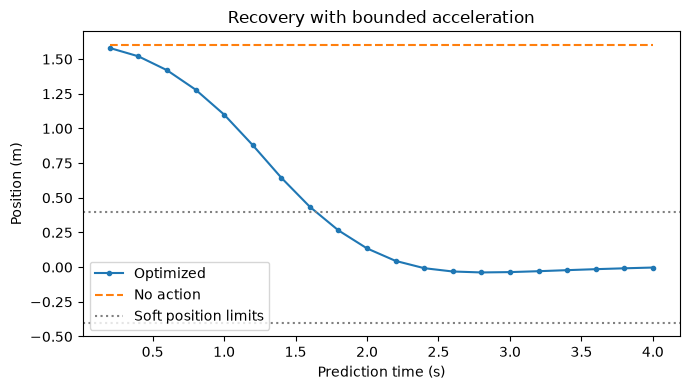

In [6]:
# Position and its soft limits share meters; no-action is a physical reference.
times = np.arange(1, 21) * 0.2
no_action = predict_states([1.6, 0.0], np.zeros(20))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(times, prediction[:, 0], marker="o", markersize=3, label="Optimized")
ax.plot(times, no_action[:, 0], linestyle="--", label="No action")
ax.axhline(0.4, color="gray", linestyle=":", label="Soft position limits")
ax.axhline(-0.4, color="gray", linestyle=":")
ax.set(xlabel="Prediction time (s)", ylabel="Position (m)", title="Recovery with bounded acceleration")
ax.legend()
fig.tight_layout()
plt.show()


The optimized position moves toward the desired interval over several control steps, while doing nothing leaves the initial offset unchanged. Early position violation is compatible with this policy, not evidence that the hard actuator row was relaxed. The figure is an open-loop prediction under the stated model; it does not include measurement noise, an independent plant, estimation error or subsequent disturbance impulses. Those limitations matter before interpreting recovery as operational assurance.


Reuse is permitted because a new measured state changes q and the shifted state bounds but leaves P, A and penalty weights fixed. Construct a workspace once, then update it using the first predicted state as an illustrative next measurement. This is a deterministic model step, not a claim that the real state will equal its forecast. The update API validates vector shapes and finite-side structure before changing the native workspace.


In [7]:
# Preserve factorization and warm state only across the documented vector changes.
workspace = PreparedSolver(problem, "asymmetric", **accurate)
next_problem = mpc(True, True, float(prediction[0, 0]), float(prediction[0, 1]))
workspace.update(q=next_problem.q, lower=next_problem.lower, upper=next_problem.upper)
next_result = workspace.solve()
print("Vector updates:", workspace.update_count)
print(f"Next-state first acceleration: {next_result['x'][0]:.6f} m/s²")


Vector updates: 1
Next-state first acceleration: -1.000000 m/s²


Inspect the controls themselves as a separate acceleration-valued figure. Compare the initial horizon with the shifted-state horizon to see what was reused and what changed. Numerical agreement of the static formulation does not imply that successive controls should be identical: the state input and remaining recovery problem have changed. The hard lines remain fixed because the physical actuator policy did not change with the measurement.


Each acceleration acts over its full sampling interval, beginning at time zero. Both horizons use their own relative time origin; predicted positions are timestamped at interval ends.

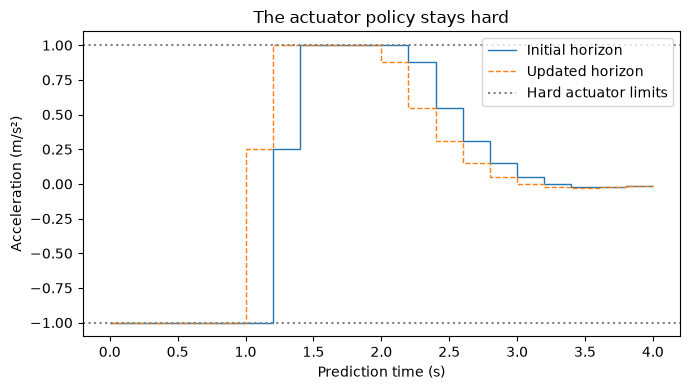

In [8]:
# A separate axis avoids mixing actuator units with the position plot.
control_edges = np.arange(len(native["x"]) + 1) * 0.2
fig, ax = plt.subplots(figsize=(7, 4))
ax.stairs(native["x"], control_edges, baseline=None, label="Initial horizon")
ax.stairs(next_result["x"], control_edges, baseline=None, linestyle="--", label="Updated horizon")
ax.axhline(1.0, color="gray", linestyle=":", label="Hard actuator limits")
ax.axhline(-1.0, color="gray", linestyle=":")
ax.set(xlabel="Prediction time (s)", ylabel="Acceleration (m/s²)", title="The actuator policy stays hard")
ax.legend()
fig.tight_layout()
plt.show()


Both control sequences remain within the declared actuator interval, even while their predicted positions initially violate a soft target. The first controls saturate because moving toward the target is valuable and acceleration is limited. Later differences arise from the updated state rather than from modifying weights. The plot demonstrates model-level policy preservation for these computed horizons; it cannot demonstrate robustness to disturbances that were never supplied to either solve.


### Using it on your own data

To substitute a measured state into this exact double-integrator model, call `mpc(True, True, initial_position, initial_velocity)` with metres and metres per second. That call changes the objective vector and shifted state bounds. The prepared workspace accepts `q`, `lower` and `upper` updates only while the Hessian, constraint matrix, hard mask and finite-side structure remain compatible. A change of sampling period, horizon or dynamics requires a new problem construction and new preparation. Silently retaining old factors after such a structural change would solve the wrong system.

The exchange path adds further constraints. A solve request contains `schema_version`, `case_id`, `base_sha256`, `lower_multiplier`, `upper_multiplier` and `quadratic_multiplier`. The checksum binds the edit to a specific original record; it is not a substitute for comparing actual problem coefficients. Linear multipliers lie between 0.01 and 100, while the quadratic multiplier may be zero to explicitly request a pure linear penalty. An omitted multiplier is malformed input, not an instruction to choose a convenient default. None of those fields can soften an actuator row.

The local export nests the complete `request` and `result` and records the numerical `environment`. Its result must still carry original row policy and units. A consumer recomputes the objective and violations before accepting the imported vector, so a claimed small error in a file does not establish its truth. The example envelope below is read for field teaching only; the trajectory in this lesson is freshly solved and is not taken from that saved example.

The recorded stream has a different role: `case_id`, `protocol_id`, `engine_source`, `specification`, `frames`, `counts` and `limitations` tie a sequence to its fixed protocol. It distinguishes workspace setup, vector updates and subsequent solves rather than relabeling every operation as a warm solve. This lesson's one next-state update illustrates the interface; it does not rerun or replace those recorded timings. The published stream also preserves source identity, which a matching package version string alone cannot establish.

At the application boundary, `readiness` has `product_version`, `catalog_sha256` and one entry per contract. A stale version or missing document is rendered explicitly. The dormant API is described by the OpenAPI paths but has no running solver service here; the unavailable example's `detail` explains the missing read-only response. Absence of that lane must never trigger an invented control signal. The actual operation list is `validate`, `assemble`, `solve`, `evaluate`, `export`: admit inputs, construct the original problem, execute its compatible method, independently evaluate its result, then serialize all states. The stages folder contains no trained predictor, training operation or checkpoint for this controller.


In [9]:
# Expose exchange meanings without treating the saved example as a new solution.
print('Request', request_example["schema_version"], sorted(request_example))
print('Local envelope', local_example["schema_version"], sorted(local_example))
print('Stream', stream["schema_version"], stream["case_id"], sorted(stream["specification"]))
print('Readiness', readiness["schema"], sorted(readiness["contracts"][0]))
print('Dormant API', sorted(api_description["paths"]), api_missing["detail"])


Request softqp.run-request/v1 ['base_sha256', 'case_id', 'lower_multiplier', 'quadratic_multiplier', 'schema_version', 'upper_multiplier']
Local envelope softqp.local-export/v1 ['environment', 'request', 'result', 'schema_version']
Stream softqp.stream/v1 C12 ['case_id', 'dt_seconds', 'frames', 'horizon', 'initial_state', 'methods', 'modes', 'policy', 'timing', 'velocity_impulses']
Readiness softqp.readiness/v2 ['id', 'missing', 'provenance', 'reason', 'state', 'status', 'version']
Dormant API ['/api/artifacts/{rel_path}', '/api/cases', '/api/cases/{case_id}/manifest', '/api/readiness', '/health', '/healthz'] {'state': 'missing', 'reason': {'en': 'The pipeline has not baked this build.', 'es': 'El pipeline no ha generado esta versión.'}}


### Sensitivity to the price of upper state departures

Increase only the upper-side state prices while retaining the same initial condition, matrices, actuator mask and lower prices. For each factor we solve through the public package and propagate the returned controls through `predict_states`. The plotted quantity is the sum of positive position departures above 0.4 metres multiplied by the sampling period, an approximation to departure area in metre seconds. Velocity departures are deliberately excluded from that quantity because they have another unit.

The sweep is an instructional intervention on declared economics, not a timing benchmark or a search over the frozen campaign. The factor one recovers the policy used above. More expensive upper departures can change how rapidly the predicted position returns, but they cannot make the first state physically reachable inside the target band while the same actuator interval holds. A large finite price should therefore never be interpreted as a guarantee that all state predictions become hard-feasible.


0.25: 1.869e-09
1: 2.570e-09
4: 1.279e-09
16: 2.028e-09


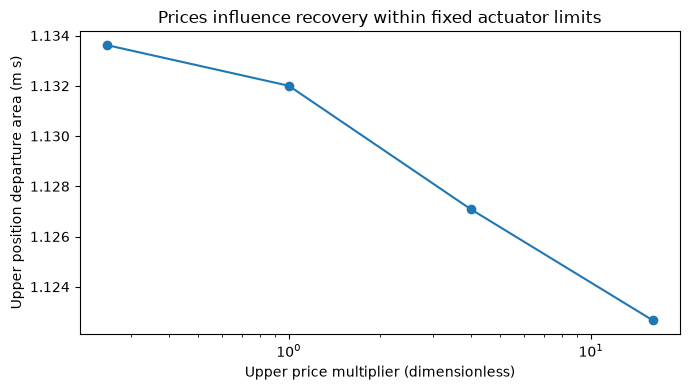

In [10]:
# Prices change the recovery policy while the actuator mask and bounds stay fixed.
multipliers = np.array([0.25, 1.0, 4.0, 16.0])
departure_areas = []
for multiplier in multipliers:
    varied_penalty = replace(problem.penalty,
                            upper_linear=problem.penalty.upper_linear * multiplier,
                            upper_quadratic=problem.penalty.upper_quadratic * multiplier)
    varied_problem = replace(problem, penalty=varied_penalty)
    varied_result = solve(varied_problem, "asymmetric", **accurate)
    varied_states = predict_states([1.6, 0.0], varied_result["x"])
    departure_areas.append(float(np.maximum(varied_states[:, 0] - 0.4, 0).sum() * 0.2))
    print(f"{multiplier:g}: {varied_result['metrics']['hard_violation']:.3e}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(multipliers, departure_areas, marker="o")
ax.set(xscale="log",
       xlabel='Upper price multiplier (dimensionless)',
       ylabel='Upper position departure area (m s)',
       title='Prices influence recovery within fixed actuator limits')
fig.tight_layout()
plt.show()


The departure-area curve measures the cumulative upper-position compromise across the same four-second horizon, while the printed hard-row maxima independently retain the actuator constraint. Any diminishing change at high factors reflects the bounded ability to accelerate and competing terms of this specific objective. The plot has no sampling uncertainty because these are deterministic numerical solutions, not noisy trials. It cannot quantify closed-loop robustness, nor can it establish a runtime improvement over the unchanged registered study.


## Results

**Answer:** The first acceleration is -1.000000 m/s² and the first predicted position is 1.580000 m. The state cannot enter the desired ±0.4 m interval immediately, but the computed control respects the hard actuator interval. The independently evaluated objective gap and KKT diagnostics printed above quantify numerical agreement separately from that physical recovery limitation.

The reusable workspace solves a changed state input without rebuilding P or A. This notebook deliberately avoids a timing claim from that single update; repeated cold/warm observations belong to the registered C12 stream and should retain initial setup as a separate cost.


## Summary

Keep three records when reviewing this class of controller: the row policy, the physical trajectory and the original-space numerical checks. Condensed dynamics, a hard actuator interval and priced state rows have different roles. If an engineering requirement forbids a state departure, reclassify that row as hard and accept the possibility of infeasibility; an arbitrarily large finite price is not an equivalent safety specification.


## References

- [OSQP numerical formulation](https://osqp.org/docs/solver/).
- [Generalized slack projections](https://arxiv.org/abs/2610.35631).
- [MathWorks, QP formulation for linear MPC](https://www.mathworks.com/help/mpc/ug/optimization-problem.html).
- Authored double-integrator model and physical predictor in this repository.

- [DAQP original-scale soft-constraint weights](https://darnstrom.github.io/daqp/start/advanced/soft).
- [SoftQP original-space contracts and control implementation](https://github.com/fsantibanezleal/CAOS_SoftQP).
